# Multilevel Model: Respondents in Counties

Notebook 06 treated the county as a nuisance (clustered SEs). This notebook treats it as a level: respondents nested in counties, with state fixed effects. Three questions the single-level analysis could not answer:

1. **How much of economic perception is between counties at all?** The intraclass correlation from a null model bounds what *any* county-level variable — including local news environment — could explain.
2. **Does county context change the partisan perception gap?** Cross-level interactions between individual party ID and county economics/composition, and a random slope for party ID.
3. **What is each county's shrunken attribution gap?** Empirical-Bayes county effects, saved for merging with news-desert and other county media data.

Plus a multilevel logit for the switching model, to check notebook 06's result with a proper county random effect.

**Inputs:** `data/processed/ces_2024_attribution.csv` (from notebook 06), `data/processed/county_covariates.csv`

**Estimation note.** `statsmodels.MixedLM` does not take survey weights. Models here are unweighted with the CES weighting variables (age, education, race, party ID) as covariates — model-based rather than design-based inference. Fixed effects are compared against notebook 06's weighted estimates as a check.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

PROC_DIR    = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures')
TABLES_DIR  = Path('../outputs/tables')

d = pd.read_csv(PROC_DIR / 'ces_2024_attribution.csv')
d = d.dropna(subset=['perceived_econ', 'pid7c', 'age', 'real_pay_pct_chg_2020_2024_z']).copy()
d['age_z'] = (d['age'] - d['age'].mean()) / d['age'].std()
for v in ['log_income', 'college_share', 'white_nocollege', 'dem_share_2020']:
    d[v + '_z'] = (d[v] - d[v].mean()) / d[v].std()

print(f'N = {len(d):,} respondents | {d["county_fips"].nunique():,} counties | {d["state"].nunique()} states')
per = d.groupby('county_fips').size()
print(f'Respondents per county: median {per.median():.0f}, IQR {per.quantile(.25):.0f}-{per.quantile(.75):.0f}, max {per.max()}')

N = 56,635 respondents | 2,653 counties | 49 states
Respondents per county: median 6, IQR 2-16, max 1141


## 1. Variance decomposition

Four nested random-intercept models. The county variance at each step is what remains to be explained by county-level factors not yet in the model.

- **M0** — null: `perceived_econ ~ 1 + (1 | county)`
- **M1a** — + individual demographics and party ID (no media)
- **M1** — + individual media diet
- **M2** — + county economic record: real pay, jobs, unemployment
- **M3** — + county composition and state fixed effects

M1a matters for the news-desert question: a county's news environment would act partly *through* what residents watch, so the between-county variance that a media-environment variable could explain is bounded by M1a's county variance, not M1's.

In [2]:
demog  = 'pid7c + college + age_z + white'
media  = 'fox + msnbc + cnn + local_tv + newspaper + social'
indiv  = f'{demog} + {media}'
actual = 'real_pay_pct_chg_2020_2024_z + private_emp_pct_chg_2020_2024_z + unemp_rate_z'
comp   = 'log_income_z + college_share_z + white_nocollege_z + dem_share_2020_z'

specs = {
    'M0 null':                   'perceived_econ ~ 1',
    'M1a + demographics, party': f'perceived_econ ~ {demog}',
    'M1 + media diet':           f'perceived_econ ~ {indiv}',
    'M2 + county economy':       f'perceived_econ ~ {indiv} + {actual}',
    'M3 + composition + state':  f'perceived_econ ~ {indiv} + {actual} + {comp} + C(state)',
}
fits = {}
rows = []
for name, f in specs.items():
    m = smf.mixedlm(f, d, groups=d['county_fips']).fit(reml=True)
    fits[name] = m
    vc, ve = m.cov_re.iloc[0, 0], m.scale
    rows.append({'model': name, 'county_var': vc, 'resid_var': ve, 'ICC': vc / (vc + ve),
                 'converged': m.converged, 'llf': m.llf})
vd = pd.DataFrame(rows).set_index('model')
vd['county_var_explained_vs_M0'] = 1 - vd['county_var'] / vd.loc['M0 null', 'county_var']
vd.round(4)

,county_var,resid_var,ICC,converged,llf,county_var_explained_vs_M0
model,,,,,,
M0 null,0.0897,1.8057,0.0473,True,-97729.9133,0.0000
"M1a + demographics, party",0.0061,1.1678,0.0052,True,-84891.2301,0.9318
M1 + media diet,0.0047,1.0949,0.0043,True,-83065.1218,0.9474
M2 + county economy,0.0038,1.0946,0.0034,True,-83052.8559,0.9580
M3 + composition + state,0.0002,1.0946,0.0001,True,-83073.2744,0.9982


In [3]:
m1a, m1 = fits['M1a + demographics, party'], fits['M1 + media diet']
for name, m in [('after demographics + party (M1a)', m1a), ('after media diet too (M1)', m1)]:
    v = m.cov_re.iloc[0, 0]
    print(f'Between-county variance {name}: {v:.4f}  ->  county-effect SD {np.sqrt(v):.3f}; '
          f'a +2 SD vs -2 SD county differs by {4 * np.sqrt(v):.2f} points on the -2..+2 scale')
print()
print('This is the ceiling for any county-level media-environment effect: it can explain at most the M1a county variance.')
print()
print('For comparison, individual-level effects in M1:')
for v in ['pid7c', 'fox', 'msnbc', 'newspaper', 'college']:
    print(f'  {v:10s} {m1.params[v]:+.3f}  (se {m1.bse[v]:.3f})')

Between-county variance after demographics + party (M1a): 0.0061  ->  county-effect SD 0.078; a +2 SD vs -2 SD county differs by 0.31 points on the -2..+2 scale
Between-county variance after media diet too (M1): 0.0047  ->  county-effect SD 0.069; a +2 SD vs -2 SD county differs by 0.27 points on the -2..+2 scale

This is the ceiling for any county-level media-environment effect: it can explain at most the M1a county variance.

For comparison, individual-level effects in M1:
  pid7c      -0.309  (se 0.002)
  fox        -0.361  (se 0.013)
  msnbc      +0.588  (se 0.016)
  newspaper  +0.284  (se 0.010)
  college    +0.305  (se 0.010)


In [4]:
# Check: M1 fixed effects (unweighted mixed) vs notebook 06 weighted WLS with clustered SEs
nb06 = pd.read_csv(TABLES_DIR / 'attribution_gap_models.csv', index_col=0)['full_coef']
cmp = pd.DataFrame({'mixedlm_M1': m1.params, 'nb06_weighted_wls': nb06}).dropna().round(3)
cmp['diff'] = (cmp['mixedlm_M1'] - cmp['nb06_weighted_wls']).round(3)
print('Fixed effects: mixed model (unweighted) vs notebook 06 (weighted, county-clustered)')
print('(notebook 06 DV is the gap = perceived - county-predicted; intercepts differ by construction)')
cmp.drop(index='Intercept', errors='ignore')

Fixed effects: mixed model (unweighted) vs notebook 06 (weighted, county-clustered)
(notebook 06 DV is the gap = perceived - county-predicted; intercepts differ by construction)


,mixedlm_M1,nb06_weighted_wls,diff
cnn,0.160,0.161,-0.001
college,0.305,0.258,0.047
fox,-0.361,-0.320,-0.041
local_tv,0.011,0.032,-0.021
msnbc,0.588,0.589,-0.001
newspaper,0.284,0.298,-0.014
pid7c,-0.309,-0.298,-0.011
social,-0.031,-0.052,0.021
white,0.195,0.161,0.034


## 2. Does county context change the partisan gap?

Cross-level interactions: individual party ID × county characteristics. A positive `pid7c:X` coefficient means the partisan perception gap is *narrower* in counties high on X (since `pid7c` itself is negative — Republicans rate the economy worse).

In [5]:
m_int = smf.mixedlm(
    f'perceived_econ ~ {indiv} + {actual} + {comp} + C(state)'
    ' + pid7c:real_pay_pct_chg_2020_2024_z + pid7c:white_nocollege_z + pid7c:college_share_z + pid7c:dem_share_2020_z',
    d, groups=d['county_fips']).fit(reml=True)

print(f'converged: {m_int.converged}\n')
print(f'{"term":40s} {"coef":>8s} {"se":>7s} {"p":>7s}')
for v in ['pid7c', 'pid7c:real_pay_pct_chg_2020_2024_z', 'pid7c:white_nocollege_z',
          'pid7c:college_share_z', 'pid7c:dem_share_2020_z']:
    print(f'{v:40s} {m_int.params[v]:+8.3f} {m_int.bse[v]:7.3f} {m_int.pvalues[v]:7.3f}')

print()
print('Implied partisan gap (strong Rep minus strong Dem, 6 x pid7c slope) by county type:')
for label, z, term in [('county white non-college', -2, 'pid7c:white_nocollege_z'), ('county white non-college', +2, 'pid7c:white_nocollege_z'),
                       ('county real pay growth', -2, 'pid7c:real_pay_pct_chg_2020_2024_z'), ('county real pay growth', +2, 'pid7c:real_pay_pct_chg_2020_2024_z'),
                       ('county Dem share 2020', -2, 'pid7c:dem_share_2020_z'), ('county Dem share 2020', +2, 'pid7c:dem_share_2020_z')]:
    slope = m_int.params['pid7c'] + m_int.params[term] * z
    print(f'  {label:26s} {z:+d} SD:  gap = {6 * slope:+.2f}')

converged: True

term                                         coef      se       p
pid7c                                      -0.305   0.002   0.000
pid7c:real_pay_pct_chg_2020_2024_z         -0.005   0.002   0.014
pid7c:white_nocollege_z                    -0.022   0.003   0.000
pid7c:college_share_z                      -0.015   0.003   0.000
pid7c:dem_share_2020_z                     +0.003   0.004   0.403

Implied partisan gap (strong Rep minus strong Dem, 6 x pid7c slope) by county type:
  county white non-college   -2 SD:  gap = -1.56
  county white non-college   +2 SD:  gap = -2.09
  county real pay growth     -2 SD:  gap = -1.77
  county real pay growth     +2 SD:  gap = -1.89
  county Dem share 2020      -2 SD:  gap = -1.87
  county Dem share 2020      +2 SD:  gap = -1.79


## 3. Random slope for party ID

Does the partisan gap itself vary across counties beyond what the interactions capture?

In [6]:
# Centre party ID at independent so the random intercept is a county's mean for independents,
# not an extrapolation to pid7c = 0 (uncentred, the intercept-slope correlation goes to -1 and the fit degenerates).
d['pid7_c'] = d['pid7c'] - 4
fixed_c = f'pid7_c + {media} + college + age_z + white + {actual} + {comp}'
m_ri = smf.mixedlm(f'perceived_econ ~ {fixed_c}', d, groups=d['county_fips']).fit(reml=True)
m_rs = smf.mixedlm(f'perceived_econ ~ {fixed_c}', d, groups=d['county_fips'], re_formula='~pid7_c').fit(reml=True)

cov = m_rs.cov_re
sd_int, sd_slope = np.sqrt(cov.iloc[0, 0]), np.sqrt(cov.iloc[1, 1])
corr = cov.iloc[0, 1] / (sd_int * sd_slope) if sd_int * sd_slope > 0 else np.nan
lr = 2 * (m_rs.llf - m_ri.llf)
from scipy import stats
print(f'converged: intercept-only {m_ri.converged}, random slope {m_rs.converged}')
print(f'Random intercept SD: {sd_int:.3f}   Random slope (pid7_c) SD: {sd_slope:.4f}   corr: {corr:+.2f}')
print(f'Fixed pid7_c slope: {m_rs.params["pid7_c"]:+.3f}')
print(f'LR (random slope vs intercept-only) = {lr:.1f}, df = 2, p = {stats.chi2.sf(max(lr, 0), 2):.4f}')
if lr <= 0 or abs(corr) > 0.95:
    print('\n  -> The slope variance is NOT identified: the fit is on a boundary (LR <= 0 and/or |corr| ~ 1).')
    print('     With a median of 6 respondents per county there is not enough within-county variation in party ID')
    print('     to estimate county-specific partisan slopes. Treat the cross-level interactions in section 2 as the')
    print('     usable evidence on whether the partisan gap varies by county type.')
else:
    print(f'\n  -> across counties the partisan slope ranges roughly {m_rs.params["pid7_c"] - 2 * sd_slope:+.3f} to '
          f'{m_rs.params["pid7_c"] + 2 * sd_slope:+.3f} (±2 SD); strong-Rep minus strong-Dem gap '
          f'{6 * (m_rs.params["pid7_c"] - 2 * sd_slope):+.2f} to {6 * (m_rs.params["pid7_c"] + 2 * sd_slope):+.2f}')

converged: intercept-only True, random slope False
Random intercept SD: 0.228   Random slope (pid7_c) SD: 0.0757   corr: -0.53
Fixed pid7_c slope: -0.313
LR (random slope vs intercept-only) = -530.6, df = 2, p = 1.0000

  -> The slope variance is NOT identified: the fit is on a boundary (LR <= 0 and/or |corr| ~ 1).
     With a median of 6 respondents per county there is not enough within-county variation in party ID
     to estimate county-specific partisan slopes. Treat the cross-level interactions in section 2 as the
     usable evidence on whether the partisan gap varies by county type.


## 4. County-level attribution gap (empirical Bayes)

The random intercept from M1 is each county's average perception net of *who lives there* (party, media, education, age, race) but not net of county economics or composition — so it is the county-level analogue of notebook 06's gap, shrunk toward zero in proportion to how few respondents the county has. This is the variable to regress on news-desert status once that file is added.

In [7]:
re = pd.DataFrame({'county_fips': list(m1.random_effects.keys()),
                   'county_gap_eb': [v.iloc[0] for v in m1.random_effects.values()]})
re = re.merge(per.rename('n_respondents').reset_index(), on='county_fips')

cov_c = pd.read_csv(PROC_DIR / 'county_covariates.csv')
cg = re.merge(cov_c[['county_fips', 'state', 'population', 'swing_2024', 'dem_share_2020', 'real_pay_pct_chg_2020_2024',
                     'private_emp_pct_chg_2020_2024', 'unemp_rate', 'log_income', 'college_share', 'white_nocollege',
                     'mfg_share_2016']], on='county_fips', how='left')

# Raw county means for comparison - shows the shrinkage
raw_mean = d.groupby('county_fips')['perceived_econ'].mean().rename('raw_county_mean')
cg = cg.merge(raw_mean.reset_index(), on='county_fips')
cg['raw_county_mean_c'] = cg['raw_county_mean'] - d['perceived_econ'].mean()

print(f'Counties with EB estimate: {len(cg):,}')
print(f'SD of EB county gap: {cg["county_gap_eb"].std():.3f}   SD of raw county means (centred): {cg["raw_county_mean_c"].std():.3f}')
print()
print('Shrinkage by county size (ratio of EB SD to raw SD):')
cg['n_bin'] = pd.cut(cg['n_respondents'], [0, 5, 20, 50, 200, 10000], labels=['1-5', '6-20', '21-50', '51-200', '200+'])
print(cg.groupby('n_bin').apply(lambda g: pd.Series({'counties': len(g), 'eb_sd': g['county_gap_eb'].std(),
                                                       'raw_sd': g['raw_county_mean_c'].std()})).round(3))

Counties with EB estimate: 2,653
SD of EB county gap: 0.017   SD of raw county means (centred): 0.755

Shrinkage by county size (ratio of EB SD to raw SD):
        counties  eb_sd  raw_sd
n_bin                          
1-5       1286.0  0.007   0.965
6-20       809.0  0.014   0.505
21-50      305.0  0.024   0.349
51-200     214.0  0.036   0.283
200+        39.0  0.050   0.206


In [8]:
# What explains the county-level gap? (weighted by respondents, since EB precision scales with n)
cg_fit = cg.dropna(subset=['swing_2024', 'real_pay_pct_chg_2020_2024']).copy()
for v in ['real_pay_pct_chg_2020_2024', 'private_emp_pct_chg_2020_2024', 'unemp_rate',
          'log_income', 'college_share', 'white_nocollege', 'dem_share_2020', 'mfg_share_2016']:
    cg_fit[v + '_z'] = (cg_fit[v] - cg_fit[v].mean()) / cg_fit[v].std()

mc = smf.wls('county_gap_eb ~ real_pay_pct_chg_2020_2024_z + private_emp_pct_chg_2020_2024_z + unemp_rate_z'
             ' + log_income_z + college_share_z + white_nocollege_z + dem_share_2020_z + mfg_share_2016_z',
             data=cg_fit, weights=cg_fit['n_respondents']).fit(cov_type='HC3')
print(f'County EB gap ~ county covariates   N = {len(cg_fit):,}   R2 = {mc.rsquared:.3f}\n')
county_tab = pd.DataFrame({'coef': mc.params, 'se': mc.bse, 'p': mc.pvalues}).round(4)
county_tab

County EB gap ~ county covariates   N = 2,653   R2 = 0.233



,coef,se,p
Intercept,-0.0041,0.0013,0.0023
real_pay_pct_chg_2020_2024_z,0.0059,0.0022,0.0075
private_emp_pct_chg_2020_2024_z,-0.0039,0.0025,0.1198
unemp_rate_z,-0.0075,0.0031,0.0168
log_income_z,-0.0011,0.0026,0.6738
college_share_z,0.0098,0.0031,0.0017
white_nocollege_z,-0.0074,0.0029,0.0118
dem_share_2020_z,0.0027,0.0028,0.3361
mfg_share_2016_z,0.0039,0.0016,0.0137


County swing_2024 ~ county EB gap (respondent-weighted, HC3):
  bivariate:      coef -3.40 (se 8.68, p=0.695)  R2 0.001
  with controls:  coef +1.52 (se 6.37, p=0.811)  R2 0.413
  -> the county-level gap is NOT a detectable predictor of the county swing.
     Given the M1a county SD of ~0.08 scale points, even the point estimate implies a swing
     difference of only +0.24pp between a +1 SD and -1 SD county.


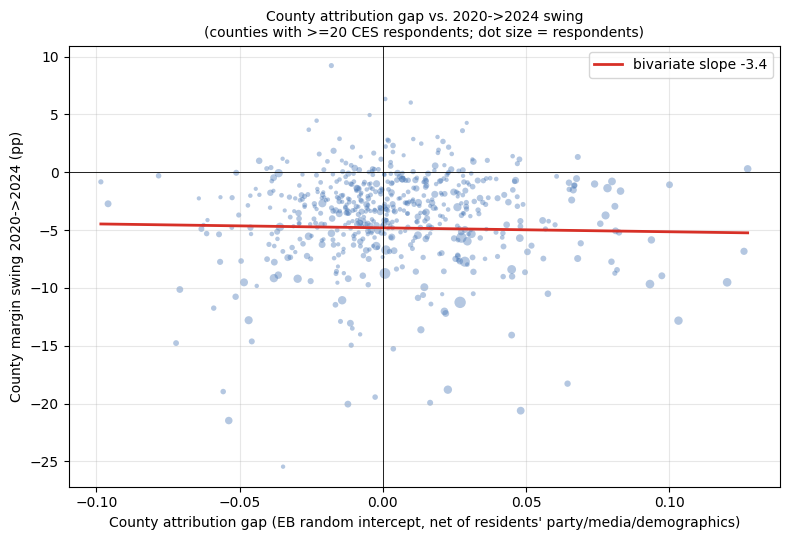

In [9]:
# Does the county gap relate to the county's 2020->2024 swing?
ms = smf.wls('swing_2024 ~ county_gap_eb', data=cg_fit, weights=cg_fit['n_respondents']).fit(cov_type='HC3')
ms2 = smf.wls('swing_2024 ~ county_gap_eb + real_pay_pct_chg_2020_2024_z + private_emp_pct_chg_2020_2024_z'
              ' + log_income_z + college_share_z + white_nocollege_z + dem_share_2020_z',
              data=cg_fit, weights=cg_fit['n_respondents']).fit(cov_type='HC3')
print('County swing_2024 ~ county EB gap (respondent-weighted, HC3):')
print(f'  bivariate:      coef {ms.params["county_gap_eb"]:+.2f} (se {ms.bse["county_gap_eb"]:.2f}, p={ms.pvalues["county_gap_eb"]:.3f})  R2 {ms.rsquared:.3f}')
print(f'  with controls:  coef {ms2.params["county_gap_eb"]:+.2f} (se {ms2.bse["county_gap_eb"]:.2f}, p={ms2.pvalues["county_gap_eb"]:.3f})  R2 {ms2.rsquared:.3f}')
sig = 'is' if ms2.pvalues['county_gap_eb'] < 0.05 else 'is NOT'
print(f'  -> the county-level gap {sig} a detectable predictor of the county swing.')
print(f'     Given the M1a county SD of ~{np.sqrt(m1a.cov_re.iloc[0, 0]):.2f} scale points, even the point estimate implies a swing')
print(f'     difference of only {2 * np.sqrt(m1a.cov_re.iloc[0, 0]) * ms2.params["county_gap_eb"]:+.2f}pp between a +1 SD and -1 SD county.')

fig, ax = plt.subplots(figsize=(8, 5.5))
big = cg_fit[cg_fit['n_respondents'] >= 20]
ax.scatter(big['county_gap_eb'], big['swing_2024'], s=np.sqrt(big['n_respondents']) * 2, alpha=0.4, color='#4575b4', linewidths=0)
xs = np.linspace(big['county_gap_eb'].min(), big['county_gap_eb'].max(), 50)
ax.plot(xs, ms.params['Intercept'] + ms.params['county_gap_eb'] * xs, color='#d73027', lw=2, label=f'bivariate slope {ms.params["county_gap_eb"]:+.1f}')
ax.axhline(0, color='black', lw=0.6); ax.axvline(0, color='black', lw=0.6)
ax.set_xlabel('County attribution gap (EB random intercept, net of residents\' party/media/demographics)')
ax.set_ylabel('County margin swing 2020->2024 (pp)')
ax.set_title('County attribution gap vs. 2020->2024 swing\n(counties with >=20 CES respondents; dot size = respondents)', fontsize=10)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'multilevel_county_gap_swing.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Multilevel logit for switching

Notebook 06's switching model with a county random intercept, fit by variational Bayes (`BinomialBayesMixedGLM`). Unweighted; posterior SDs are approximate. Takes several minutes.

In [10]:
sw = d[(d['presvote_prior_party'] == 'D') & d['voted_2024']].copy()
sw['switch_R'] = sw['vote_R_2024']
print(f'Recalled-Biden voters: N = {len(sw):,}, counties {sw["county_fips"].nunique():,}, '
      f'unweighted switch rate {sw["switch_R"].mean():.1%}')

glm = sm.BinomialBayesMixedGLM.from_formula(
    f'switch_R ~ gap + pid7c + college + age_z + white + fox + msnbc + social + {actual}',
    {'county': '0 + C(county_fips)'}, sw).fit_vb()

fe = pd.DataFrame({'post_mean': glm.fe_mean, 'post_sd': glm.fe_sd}, index=glm.model.exog_names)
fe['z'] = fe['post_mean'] / fe['post_sd']
print()
print(fe.round(3))
print()
print(f'County random-effect SD (posterior mean): {np.exp(glm.vcp_mean[0]):.3f} on the logit scale')

nb06_sw = pd.read_csv(TABLES_DIR / 'attribution_switching.csv', index_col=0)['full_coef']
print()
print('gap coefficient: notebook 06 clustered logit vs multilevel VB logit')
print(f'  nb06: {nb06_sw["gap"]:+.3f}   multilevel: {fe.loc["gap", "post_mean"]:+.3f}')

Recalled-Biden voters: N = 20,608, counties 1,919, unweighted switch rate 3.0%

                                 post_mean  post_sd        z
Intercept                           -5.173    0.049 -106.039
gap                                 -0.956    0.043  -22.004
pid7c                                0.819    0.013   65.256
college                             -0.254    0.078   -3.248
age_z                               -0.322    0.053   -6.079
white                               -0.095    0.062   -1.533
fox                                  1.637    0.108   15.202
msnbc                               -0.527    0.146   -3.612
social                              -0.349    0.055   -6.334
real_pay_pct_chg_2020_2024_z        -0.104    0.054   -1.924
private_emp_pct_chg_2020_2024_z      0.055    0.052    1.043
unemp_rate_z                         0.094    0.052    1.810

County random-effect SD (posterior mean): 0.384 on the logit scale

gap coefficient: notebook 06 clustered logit vs multilevel

## 6. Save

In [11]:
vd.to_csv(TABLES_DIR / 'multilevel_variance_decomposition.csv')
pd.DataFrame({'coef': m_int.params, 'se': m_int.bse, 'p': m_int.pvalues}).round(4).to_csv(TABLES_DIR / 'multilevel_cross_level.csv')
county_tab.to_csv(TABLES_DIR / 'multilevel_county_gap_model.csv')
fe.round(4).to_csv(TABLES_DIR / 'multilevel_switching_logit.csv')
cg.drop(columns=['n_bin']).to_csv(PROC_DIR / 'county_attribution_gap.csv', index=False)
print('Saved:')
for p in ['outputs/tables/multilevel_variance_decomposition.csv', 'outputs/tables/multilevel_cross_level.csv',
          'outputs/tables/multilevel_county_gap_model.csv', 'outputs/tables/multilevel_switching_logit.csv',
          'data/processed/county_attribution_gap.csv']:
    print('  ' + p)

Saved:
  outputs/tables/multilevel_variance_decomposition.csv
  outputs/tables/multilevel_cross_level.csv
  outputs/tables/multilevel_county_gap_model.csv
  outputs/tables/multilevel_switching_logit.csv
  data/processed/county_attribution_gap.csv


## Where the news-desert variable goes

`data/processed/county_attribution_gap.csv` has one row per county with the EB gap and respondent count. Once the Medill local-news file is in `data/raw/news_deserts/`:

1. Merge on `county_fips`; add `news_desert` (0 or 1 local outlets) and `outlets_per_100k` to the county covariates.
2. Re-run section 1 with those terms added to M1a (before individual media) — the change in `county_var` is the between-county variance the news environment explains. Section 1 already shows the ceiling: it is small. A county-level news effect on *levels* of perception is unlikely to be large; the more promising test is (3).
3. Add `pid7c:news_desert` to section 2 — the hypothesis is that the partisan gap is *wider* where local news is absent (national/partisan sources fill the gap).
4. Use `news_desert` as an instrument for perception in the switching model — the identification strategy for the reverse-causation problem flagged in notebook 06. Its exclusion restriction (news deserts affect switching only through perception) is arguable, not given.

## Limitations

- **Unweighted.** MixedLM has no survey-weight support; the M1-vs-06 comparison in section 1 shows how much that matters for the fixed effects.
- **Shrinkage.** The EB county gap is pulled toward zero for small counties. The respondent-weighted county regressions partially compensate; a county with 3 respondents has essentially no information.
- **VB posterior SDs** for the mixed logit are known to be too narrow.
- **State fixed effects absorb** any state-level media market variation; that is deliberate for now (state-level confounders) but a crossed county/state random-effects model would be the fuller specification.